# HR Analytics: Employee Attrition Prediction
## Machine Learning Zoomcamp — Midterm Project

### 1. Descripción del Problema
La rotación voluntaria de empleados (**Employee Attrition**) representa uno de los mayores costos operativos para las organizaciones: reclutar, contratar y capacitar a un reemplazo suele costar entre el 50% y el 200% del salario anual del empleado saliente.

**Objetivo del proyecto:**
Construir un modelo de Machine Learning supervisado que prediga la probabilidad de que un empleado renuncie a la compañía, permitiendo al equipo de Recursos Humanos implementar estrategias de retención personalizadas antes de que se produzca la renuncia.

**Dataset utilizado:**
IBM HR Analytics Employee Attrition dataset (1,470 filas, 35 variables demográficas, laborales y de satisfacción).

### 2. Importación de Librerías y Carga de Datos

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, accuracy_score, classification_report, roc_curve
import xgboost as xgb
import pickle

# Cargar dataset
df = pd.read_csv('data/employee_attrition.csv')
print(f'Dimensiones del dataset: {df.shape}')
df.head()

Dimensiones del dataset: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


### 3. Limpieza y Preparación de Datos
- Estandarizamos los nombres de columnas a minúsculas.
- Codificamos la variable objetivo `attrition`: `Yes -> 1`, `No -> 0`.
- Verificamos valores nulos.
- Eliminamos columnas constantes o de identificación que no aportan valor predictivo (`employeecount`, `standardhours`, `over18`, `employeenumber`).

In [2]:
# Normalizar nombres
df.columns = df.columns.str.lower()

# Variable objetivo binaria
df['target'] = (df['attrition'] == 'Yes').astype(int)
df = df.drop(columns=['attrition'])

# Comprobar valores nulos
print('Valores nulos por columna:\n', df.isnull().sum().sum())

# Eliminar columnas irrelevantes
drop_cols = ['employeecount', 'standardhours', 'over18', 'employeenumber']
df = df.drop(columns=[col for col in drop_cols if col in df.columns])
print(f'Columnas tras limpieza: {df.shape[1]}')

Valores nulos por columna:
 0
Columnas tras limpieza: 31


### 4. Análisis Exploratorio de Datos (EDA)
Analizamos la distribución de la variable objetivo y las relaciones con variables clave.

Tasa global de rotacion (Attrition rate): 16.12%
target
0    1233
1     237
Name: count, dtype: int64


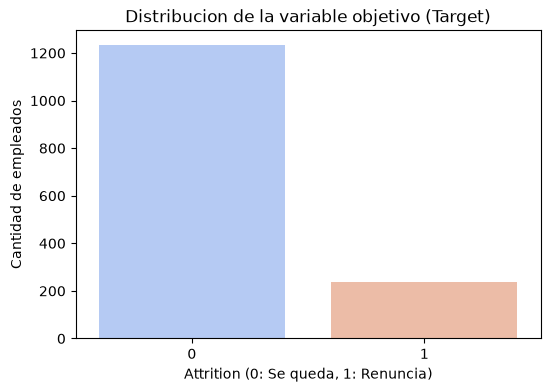

In [3]:
# Distribucion de la variable objetivo
attrition_rate = df['target'].mean()
print(f'Tasa global de rotacion (Attrition rate): {attrition_rate:.2%}')
print(df['target'].value_counts())

# Visualizar distribucion de clases
plt.figure(figsize=(6, 4))
sns.countplot(x='target', data=df, hue='target', palette='coolwarm', legend=False)
plt.title('Distribucion de la variable objetivo (Target)')
plt.xlabel('Attrition (0: Se queda, 1: Renuncia)')
plt.ylabel('Cantidad de empleados')
plt.show()

          count  attrition_rate
overtime                       
No         1054        0.104364
Yes         416        0.305288


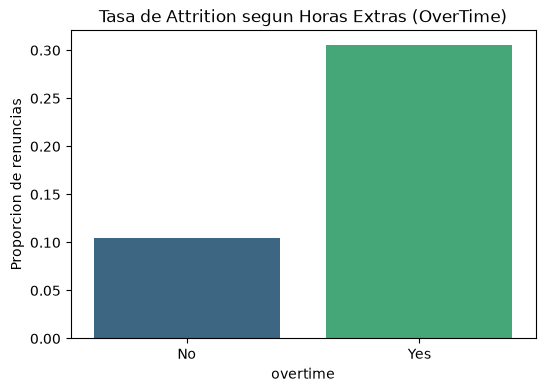

In [4]:
# Tasa de rotacion por OverTime (Horas Extras)
ot_rate = df.groupby('overtime')['target'].agg(['count', 'mean']).rename(columns={'mean': 'attrition_rate'})
print(ot_rate)

plt.figure(figsize=(6, 4))
sns.barplot(x=ot_rate.index, y=ot_rate['attrition_rate'], hue=ot_rate.index, palette='viridis', legend=False)
plt.title('Tasa de Attrition segun Horas Extras (OverTime)')
plt.ylabel('Proporcion de renuncias')
plt.show()

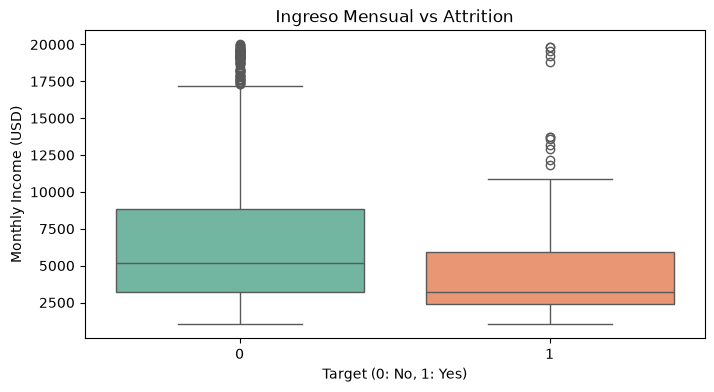

In [5]:
# Distribucion de ingresos mensuales segun rotacion
plt.figure(figsize=(8, 4))
sns.boxplot(x='target', y='monthlyincome', data=df, hue='target', palette='Set2', legend=False)
plt.title('Ingreso Mensual vs Attrition')
plt.xlabel('Target (0: No, 1: Yes)')
plt.ylabel('Monthly Income (USD)')
plt.show()

### 5. División del Dataset
- 60% Entrenamiento (*Train*)
- 20% Validación (*Validation*)
- 20% Prueba final (*Test*)
Estratificado por la variable objetivo para conservar la proporción de clases.

In [6]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42, stratify=df['target'])
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=42, stratify=df_full_train['target'])

y_train = df_train.pop('target').values
y_val = df_val.pop('target').values
y_test = df_test.pop('target').values

print(f'Train size: {len(df_train)}, Val size: {len(df_val)}, Test size: {len(df_test)}')

# Vectorizacion con DictVectorizer
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(df_train.to_dict(orient='records'))
X_val = dv.transform(df_val.to_dict(orient='records'))
X_test = dv.transform(df_test.to_dict(orient='records'))

print(f'Numero total de variables tras one-hot encoding: {X_train.shape[1]}')

Train size: 882, Val size: 294, Test size: 294
Numero total de variables tras one-hot encoding: 51


### 6. Entrenamiento y Comparación de Modelos
Entrenamos y evaluamos 4 familias de modelos en el conjunto de validación:
1. **Logistic Regression**
2. **Decision Tree Classifier**
3. **Random Forest Classifier**
4. **XGBoost Classifier**

In [7]:
# 1. Logistic Regression
lr = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
lr.fit(X_train, y_train)
y_pred_lr = lr.predict_proba(X_val)[:, 1]
auc_lr = roc_auc_score(y_val, y_pred_lr)
print(f'Logistic Regression Val AUC: {auc_lr:.4f}')

# 2. Decision Tree
dt = DecisionTreeClassifier(max_depth=5, min_samples_leaf=10, random_state=42)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict_proba(X_val)[:, 1]
auc_dt = roc_auc_score(y_val, y_pred_dt)
print(f'Decision Tree Val AUC:       {auc_dt:.4f}')

# 3. Random Forest
rf = RandomForestClassifier(n_estimators=100, max_depth=10, min_samples_leaf=3, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict_proba(X_val)[:, 1]
auc_rf = roc_auc_score(y_val, y_pred_rf)
print(f'Random Forest Val AUC:       {auc_rf:.4f}')

# 4. XGBoost
feature_names = [f.replace('=', '_').replace(' ', '_').replace('<', '_') for f in dv.get_feature_names_out()]
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=feature_names)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=feature_names)
params = {'eta': 0.1, 'max_depth': 4, 'objective': 'binary:logistic', 'eval_metric': 'auc', 'seed': 42, 'verbosity': 0}
model_xgb = xgb.train(params, dtrain, num_boost_round=100)
y_pred_xgb = model_xgb.predict(dval)
auc_xgb = roc_auc_score(y_val, y_pred_xgb)
print(f'XGBoost Val AUC:             {auc_xgb:.4f}')

Logistic Regression Val AUC: 0.8308
Decision Tree Val AUC:       0.7584
Random Forest Val AUC:       0.8393


XGBoost Val AUC:             0.7808


### 7. Afinamiento de Hiperparámetros con Validación Cruzada (5-Fold CV)
Afinamos los parámetros del mejor modelo en `df_full_train` usando 5-Fold Cross Validation.

In [8]:
# Cross Validation para Logistic Regression
y_full = df_full_train['target'].values
df_full_features = df_full_train.drop(columns=['target'])
kf = KFold(n_splits=5, shuffle=True, random_state=42)

print('Afinamiento de Logistic Regression (parametro C):')
c_results = {}
for c in [0.01, 0.1, 1.0, 10.0]:
    scores = []
    for tr_idx, val_idx in kf.split(df_full_features):
        d_tr = df_full_features.iloc[tr_idx].to_dict(orient='records')
        d_va = df_full_features.iloc[val_idx].to_dict(orient='records')
        y_tr, y_va = y_full[tr_idx], y_full[val_idx]
        
        dv_cv = DictVectorizer(sparse=False)
        X_tr = dv_cv.fit_transform(d_tr)
        X_va = dv_cv.transform(d_va)
        
        m = LogisticRegression(solver='liblinear', C=c, max_iter=1000, random_state=42)
        m.fit(X_tr, y_tr)
        scores.append(roc_auc_score(y_va, m.predict_proba(X_va)[:, 1]))
    c_results[c] = (np.mean(scores), np.std(scores))
    print(f'  C={c:5.2f} -> Mean AUC: {c_results[c][0]:.4f} +/- {c_results[c][1]:.4f}')

Afinamiento de Logistic Regression (parametro C):
  C= 0.01 -> Mean AUC: 0.7738 +/- 0.0515


  C= 0.10 -> Mean AUC: 0.8049 +/- 0.0339
  C= 1.00 -> Mean AUC: 0.8039 +/- 0.0415


  C=10.00 -> Mean AUC: 0.8093 +/- 0.0314


### 8. Evaluación Final en el Conjunto de Prueba (*Test Set*)
Entrenamos el modelo final con `df_full_train` y evaluamos sobre `df_test` no visto.

In [9]:
# Entrenamiento final en full_train
dv_final = DictVectorizer(sparse=False)
X_full_train = dv_final.fit_transform(df_full_features.to_dict(orient='records'))
X_test_final = dv_final.transform(df_test.to_dict(orient='records'))

final_model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
final_model.fit(X_full_train, y_full)

# Prediccion en test
test_probs = final_model.predict_proba(X_test_final)[:, 1]
test_preds = (test_probs >= 0.5).astype(int)

test_auc = roc_auc_score(y_test, test_probs)
test_acc = accuracy_score(y_test, test_preds)

print(f'=== RESULTADOS FINALES EN TEST ===')
print(f'ROC-AUC:  {test_auc:.4f}')
print(f'Accuracy: {test_acc:.4f}')
print('\nReporte de clasificacion:')
print(classification_report(y_test, test_preds, target_names=['Retenido (0)', 'Renuncia (1)']))

=== RESULTADOS FINALES EN TEST ===
ROC-AUC:  0.8053
Accuracy: 0.8878

Reporte de clasificacion:
              precision    recall  f1-score   support

Retenido (0)       0.88      1.00      0.94       247
Renuncia (1)       0.94      0.32      0.48        47

    accuracy                           0.89       294
   macro avg       0.91      0.66      0.71       294
weighted avg       0.89      0.89      0.86       294



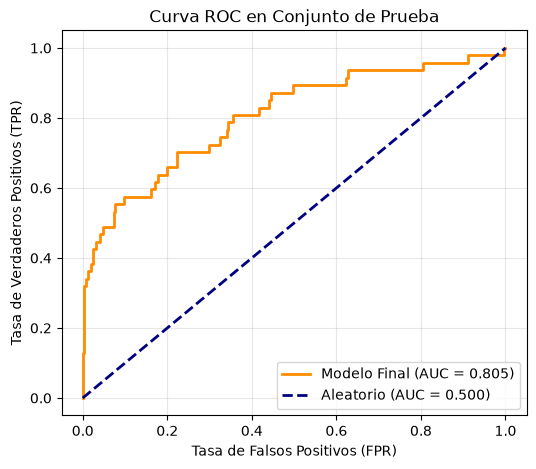

In [10]:
# Curva ROC en Test
fpr, tpr, _ = roc_curve(y_test, test_probs)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'Modelo Final (AUC = {test_auc:.3f})', color='darkorange', lw=2)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Aleatorio (AUC = 0.500)')
plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR)')
plt.title('Curva ROC en Conjunto de Prueba')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.show()

### 9. Importancia de Variables (Coeficientes del Modelo)
Identificamos qué factores incrementan más la probabilidad de renuncia.

In [11]:
# Coeficientes
coef_df = pd.DataFrame({
    'feature': dv_final.get_feature_names_out(),
    'coef': final_model.coef_[0]
}).sort_values(by='coef', ascending=False)

print('Top 5 caracteristicas que aumentan el riesgo de renuncia:')
print(coef_df.head(5))

print('\nTop 5 caracteristicas que aumentan la retencion (coeficiente negativo):')
print(coef_df.tail(5))

Top 5 caracteristicas que aumentan el riesgo de renuncia:
                             feature      coef
39                      overtime=Yes  0.871518
2   businesstravel=Travel_Frequently  0.567238
24     jobrole=Laboratory Technician  0.540231
41                 performancerating  0.479630
34              maritalstatus=Single  0.454178

Top 5 caracteristicas que aumentan la retencion (coeficiente negativo):
                       feature      coef
16     environmentsatisfaction -0.283224
28  jobrole=Research Scientist -0.299972
43            stockoptionlevel -0.303441
1    businesstravel=Non-Travel -0.343530
38                 overtime=No -0.662356


### 10. Guardar el Artefacto del Modelo
Exportamos el vectorizador `DictVectorizer` y el modelo entrenado a `model.bin` con `pickle`.

In [12]:
with open('model.bin', 'wb') as f_out:
    pickle.dump((dv_final, final_model), f_out)

print('Modelo y vectorizador guardados exitosamente en model.bin')

Modelo y vectorizador guardados exitosamente en model.bin
